In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("chinook.db")

def run_query(query):
    return pd.read_sql_query(query, conn)


## Q1. Write a query to list the top 10 genres with the highest number of tracks. (Show in bar plot)

,Genre,Track_Count
0,Rock,1297
1,Latin,579
2,Metal,374
3,Alternative & Punk,332
4,Jazz,130
5,TV Shows,93
6,Blues,81
7,Classical,74
8,Drama,64
9,R&B/Soul,61


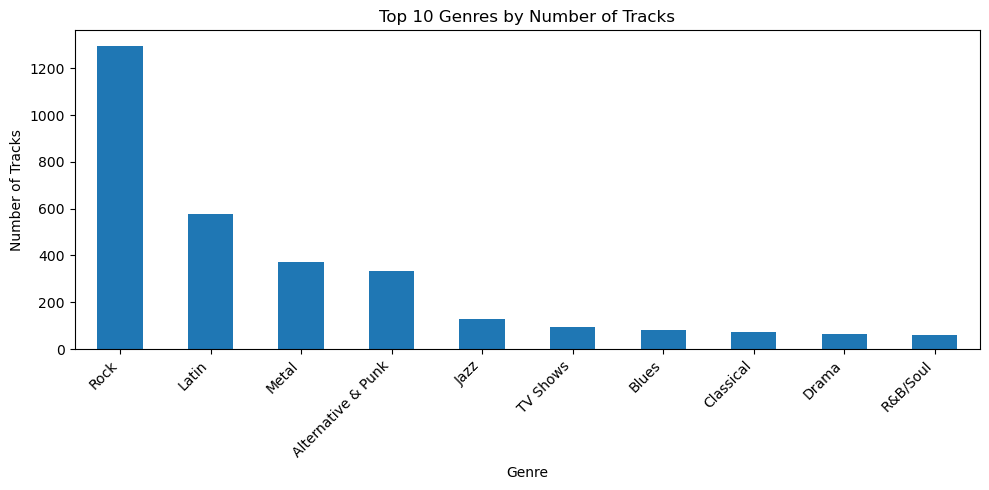

In [2]:
# Q1. Top 10 genres with the highest number of tracks (bar plot)
query = """
SELECT g.name AS Genre, COUNT(t.track_id) AS Track_Count
FROM genre g
JOIN track t ON t.genre_id = g.genre_id
GROUP BY g.genre_id, g.name
ORDER BY Track_Count DESC
LIMIT 10;
"""
df_q1 = run_query(query)
display(df_q1)

df_q1.plot(kind="bar", x="Genre", y="Track_Count", legend=False, figsize=(10, 5))
plt.title("Top 10 Genres by Number of Tracks")
plt.xlabel("Genre")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Q2. Write a query to list the top 10 albums that contain the most tracks.

In [3]:
# Q2. Top 10 albums that contain the most tracks
query = """
SELECT al.title AS Album, ar.name AS Artist, COUNT(t.track_id) AS Track_Count
FROM album al
JOIN artist ar ON ar.artist_id = al.artist_id
JOIN track t ON t.album_id = al.album_id
GROUP BY al.album_id, al.title, ar.name
ORDER BY Track_Count DESC, al.title
LIMIT 10;
"""
df_q2 = run_query(query)
display(df_q2)


,Album,Artist,Track_Count
0,Greatest Hits,Lenny Kravitz,57
1,Minha Historia,Chico Buarque,34
2,Unplugged,Eric Clapton,30
3,"Lost, Season 3",Lost,26
4,"Lost, Season 1",Lost,25
5,"The Office, Season 3",The Office,25
6,"Battlestar Galactica (Classic), Season 1",Battlestar Galactica (Classic),24
7,"Lost, Season 2",Lost,24
8,My Way: The Best Of Frank Sinatra [Disc 1],Frank Sinatra,24
9,Afrociberdelia,Chico Science & Nação Zumbi,23


## Q3. Write a query to find the top 10 customers who spent the most money.

In [4]:
# Q3. Top 10 customers who spent the most money
query = """
SELECT c.customer_id,
       c.first_name || ' ' || c.last_name AS Customer,
       ROUND(SUM(i.total), 2) AS Total_Spent
FROM customer c
JOIN invoice i ON i.customer_id = c.customer_id
GROUP BY c.customer_id, Customer
ORDER BY Total_Spent DESC
LIMIT 10;
"""
df_q3 = run_query(query)
display(df_q3)


,customer_id,Customer,Total_Spent
0,5,František Wichterlová,144.54
1,6,Helena Holý,128.70
2,46,Hugh O'Reilly,114.84
3,58,Manoj Pareek,111.87
4,1,Luís Gonçalves,108.90
5,13,Fernanda Ramos,106.92
6,34,João Fernandes,102.96
7,3,François Tremblay,99.99
8,42,Wyatt Girard,99.99
9,17,Jack Smith,98.01


## Q4. Write a query to find the top 5 artists who generated the highest revenue from track sales.

In [5]:
# Q4. Top 5 artists who generated the highest revenue from track sales
query = """
SELECT ar.name AS Artist,
       ROUND(SUM(il.unit_price * il.quantity), 2) AS Revenue
FROM artist ar
JOIN album al ON al.artist_id = ar.artist_id
JOIN track t ON t.album_id = al.album_id
JOIN invoice_line il ON il.track_id = t.track_id
GROUP BY ar.artist_id, ar.name
ORDER BY Revenue DESC
LIMIT 5;
"""
df_q4 = run_query(query)
display(df_q4)


,Artist,Revenue
0,Queen,190.08
1,Jimi Hendrix,185.13
2,Nirvana,128.70
3,Red Hot Chili Peppers,128.70
4,Pearl Jam,127.71


## Q5. Countries by Average Revenue per Invoice

In [6]:
# Q5. Countries by average revenue per invoice
query = """
SELECT billing_country AS Country,
       COUNT(invoice_id) AS Invoice_Count,
       ROUND(AVG(total), 2) AS Average_Revenue_Per_Invoice,
       ROUND(SUM(total), 2) AS Total_Revenue
FROM invoice
GROUP BY billing_country
ORDER BY Average_Revenue_Per_Invoice DESC;
"""
df_q5 = run_query(query)
display(df_q5)


,Country,Invoice_Count,Average_Revenue_Per_Invoice,Total_Revenue
0,Czech Republic,30,9.11,273.24
1,Spain,11,8.91,98.01
2,Ireland,13,8.83,114.84
3,United Kingdom,28,8.77,245.52
4,India,21,8.72,183.15
5,Belgium,7,8.63,60.39
6,Germany,41,8.16,334.62
7,Australia,10,8.12,81.18
8,Norway,9,8.03,72.27
9,USA,131,7.94,1040.49


## Q6. Write a query to find the media type with number of tracks.


In [7]:
# Q6. Media type with number of tracks
query = """
SELECT mt.name AS Media_Type, COUNT(t.track_id) AS Track_Count
FROM media_type mt
JOIN track t ON t.media_type_id = mt.media_type_id
GROUP BY mt.media_type_id, mt.name
ORDER BY Track_Count DESC;
"""
df_q6 = run_query(query)
display(df_q6)


,Media_Type,Track_Count
0,MPEG audio file,3034
1,Protected AAC audio file,237
2,Protected MPEG-4 video file,214
3,AAC audio file,11
4,Purchased AAC audio file,7


## Q7. Which artists have released tracks in more than one genre?

In [8]:
# Q7. Artists who have released tracks in more than one genre
query = """
SELECT ar.name AS Artist,
       COUNT(DISTINCT t.genre_id) AS Number_Of_Genres
FROM artist ar
JOIN album al ON al.artist_id = ar.artist_id
JOIN track t ON t.album_id = al.album_id
WHERE t.genre_id IS NOT NULL
GROUP BY ar.artist_id, ar.name
HAVING COUNT(DISTINCT t.genre_id) > 1
ORDER BY Number_Of_Genres DESC, Artist;
"""
df_q7 = run_query(query)
display(df_q7)


,Artist,Number_Of_Genres
0,Iron Maiden,4
1,Audioslave,3
2,Battlestar Galactica,3
3,Gilberto Gil,3
4,Jamiroquai,3
5,Lenny Kravitz,3
6,Various Artists,3
7,Amy Winehouse,2
8,Antônio Carlos Jobim,2
9,Eric Clapton,2


## Q8. Write a query to list the top 10 longest tracks by duration.

In [9]:
# Q8. Top 10 longest tracks by duration
query = """
SELECT name AS Track,
       milliseconds AS Duration_Milliseconds,
       ROUND(milliseconds / 60000.0, 2) AS Duration_Minutes
FROM track
ORDER BY milliseconds DESC
LIMIT 10;
"""
df_q8 = run_query(query)
display(df_q8)


,Track,Duration_Milliseconds,Duration_Minutes
0,Occupation / Precipice,5286953,88.12
1,Through a Looking Glass,5088838,84.81
2,"Greetings from Earth, Pt. 1",2960293,49.34
3,The Man With Nine Lives,2956998,49.28
4,"Battlestar Galactica, Pt. 2",2956081,49.27
5,"Battlestar Galactica, Pt. 1",2952702,49.21
6,Murder On the Rising Star,2935894,48.93
7,"Battlestar Galactica, Pt. 3",2927802,48.80
8,Take the Celestra,2927677,48.79
9,Fire In Space,2926593,48.78


## Q9. Top 5 Revenue Share percentage by Artist (Pie Chart)

,Artist,Revenue,Revenue_Share_Percent
0,Queen,190.08,4.04
1,Jimi Hendrix,185.13,3.93
2,Nirvana,128.70,2.73
3,Red Hot Chili Peppers,128.70,2.73
4,Pearl Jam,127.71,2.71


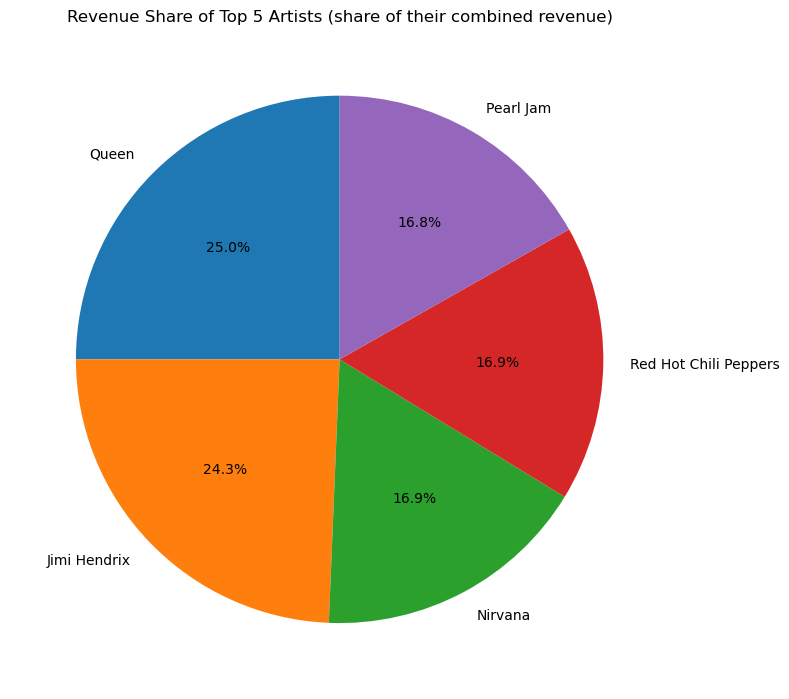

In [10]:
# Q9. Top 5 artists' revenue share percentage (pie chart)
# Revenue share is calculated against total revenue across all artists.
query = """
WITH artist_revenue AS (
    SELECT ar.artist_id, ar.name AS Artist,
           SUM(il.unit_price * il.quantity) AS Revenue
    FROM artist ar
    JOIN album al ON al.artist_id = ar.artist_id
    JOIN track t ON t.album_id = al.album_id
    JOIN invoice_line il ON il.track_id = t.track_id
    GROUP BY ar.artist_id, ar.name
),
top_artists AS (
    SELECT Artist, Revenue
    FROM artist_revenue
    ORDER BY Revenue DESC
    LIMIT 5
)
SELECT Artist, ROUND(Revenue, 2) AS Revenue,
       ROUND(100.0 * Revenue / (SELECT SUM(Revenue) FROM artist_revenue), 2) AS Revenue_Share_Percent
FROM top_artists
ORDER BY Revenue DESC;
"""
df_q9 = run_query(query)
display(df_q9)

plt.figure(figsize=(8, 8))
plt.pie(df_q9["Revenue"], labels=df_q9["Artist"], autopct="%1.1f%%", startangle=90)
plt.title("Revenue Share of Top 5 Artists (share of their combined revenue)")
plt.tight_layout()
plt.show()


## Q10. Revenue by Genre (Rock, Latin, Metal) in Each Country (Stacked Column Chart)

,Country,Genre,Revenue
0,Argentina,Latin,1.98
1,Argentina,Metal,1.98
2,Argentina,Rock,10.89
3,Australia,Latin,1.98
4,Australia,Metal,13.86
...,...,...,...
65,USA,Metal,122.76
66,USA,Rock,555.39
67,United Kingdom,Latin,6.93
68,United Kingdom,Metal,30.69


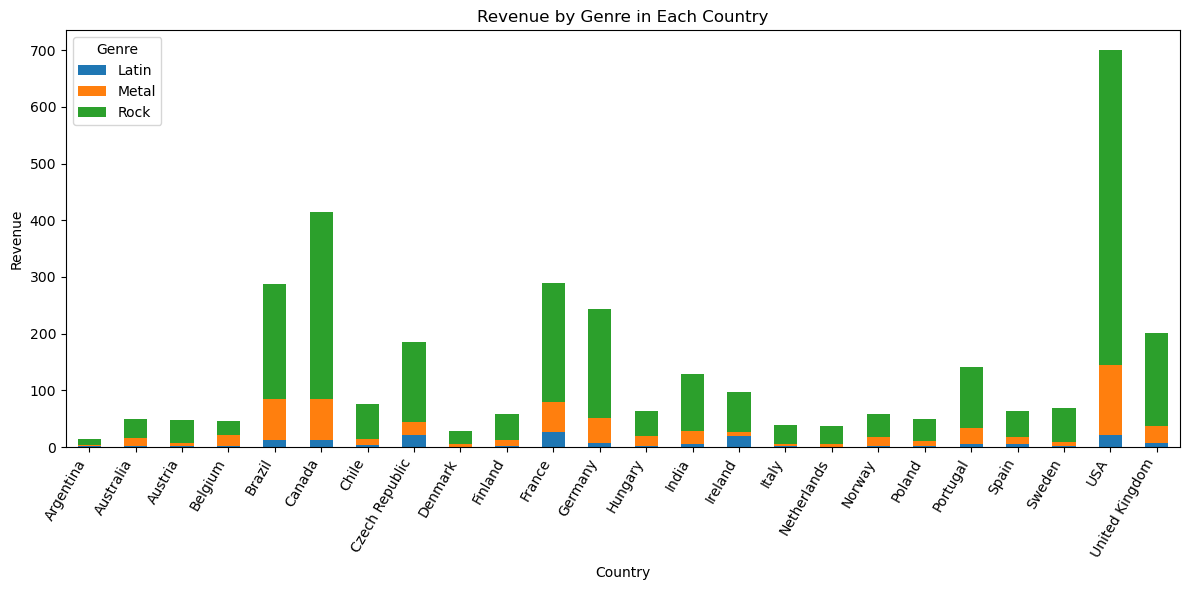

In [11]:
# Q10. Revenue by genre (Rock, Latin, Metal) in each country (stacked column chart)
query = """
SELECT i.billing_country AS Country,
       g.name AS Genre,
       ROUND(SUM(il.unit_price * il.quantity), 2) AS Revenue
FROM invoice i
JOIN invoice_line il ON il.invoice_id = i.invoice_id
JOIN track t ON t.track_id = il.track_id
JOIN genre g ON g.genre_id = t.genre_id
WHERE g.name IN ('Rock', 'Latin', 'Metal')
GROUP BY i.billing_country, g.name
ORDER BY i.billing_country;
"""
df_q10 = run_query(query)
display(df_q10)

pivot_q10 = df_q10.pivot(index="Country", columns="Genre", values="Revenue").fillna(0)
pivot_q10.plot(kind="bar", stacked=True, figsize=(12, 6))
plt.title("Revenue by Genre in Each Country")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=60, ha="right")
plt.legend(title="Genre")
plt.tight_layout()
plt.show()

# Close the database connection when finished
conn.close()
